<a href="https://colab.research.google.com/github/Roseille/BME-i9400-2026/blob/lab01/checkins/Roseille_lab01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max"]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?

### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [23]:
indexes = []
for index in range(len(data)):
  if (data['body_fat_pct'][index] <= 0) or (data['height_in'][index] < 50):
    indexes.append(index)
suspect = data.loc[indexes]

In [24]:
print(suspect)

     case  body_fat_pct  density  age  weight_lb  height_in   bmi  neck  \
41     42          32.9   1.0250   44      205.0       29.5  29.9  36.6   
181   182           0.0   1.1089   40      118.5       68.0  18.1  33.8   

     chest  abdomen    hip  thigh  knee  ankle  biceps  forearm  wrist  
41   106.0    104.3  115.5   70.6  42.5   23.7    33.6     28.7   17.4  
181   79.3     69.4   85.0   47.2  33.5   20.2    27.7     24.6   16.5  


In [25]:
# --- TODO: find the implausible rows ---
#BMI is Weight in lbs * 703/ Height^2 in inch^2 => Height = sqrt(weight*703/bmi)
suspect = suspect        # a DataFrame: the rows with height_in < 50 or body_fat_pct <= 0

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect.index

Index([41, 181], dtype='int64')

In [26]:
df_copy = data.copy()
for index in suspect.index:
  if df_copy.loc[index]['height_in'] < 50:
    df_copy.loc[index]['height_in'] = np.sqrt(df_copy.loc[index]['weight_lb'] * 703 / df_copy.loc[index]['bmi'])
  elif df_copy.loc[index]['body_fat_pct'] <= 0:
    df_copy = df_copy.drop(index)

/tmp/ipykernel_1097/1270044649.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_copy.loc[index]['height_in'] = np.sqrt(df_copy.loc[index]['weight_lb'] * 703 / df_copy.loc[index]['bmi'])


In [27]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
# For a row you correct, change the value; for a row you remove, drop it; for a row you keep, do nothing.
clean = df_copy

assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

251 men remain after your decisions (1 removed)


**Answer 2.1** — For each row you flagged: what is wrong, what you did, and why.
Within the two conditionals, only 2 rows had errors, and they were different, which tells me that there isn't a systematic error but it's likely a manual input error, so then the solution is just to correct those values given the other available data. If multiple rows had the same type of error, I would've recalculated the values of that column for all patients, or if one individual had multiple errors, to the point where certain values couldn't be derived based on the available data/conflicting information, I would just drop that subject's data. In this specific case, height_in can just be recalculated assuming weight and bmi are correct. For case 41, the height comes out to be sqrt(703 x weight/BMI) = sqrt(703 x 205/299) = 69.425 in = 5'7", which is reasonable. Using Siri's equation, we can calculate the body fat percentage for row 181, 495/density - 450 = 495/1.0250 - 450 = -3.611 which doesn't make sense. Doing the same calculation for row 41 results in the density matching the body fat percentage given in the table, indicating that subject 181 has corrupt data and should be dropped from the data set.

### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [28]:
from sklearn.linear_model import LinearRegression
predictors = df_copy.drop(columns = ['case', 'body_fat_pct']).columns.tolist()
model = LinearRegression().fit(df_copy[predictors], df_copy['body_fat_pct'])

for name, coef in zip(predictors, model.coef_):
    print(f"{name}: {coef:.4f}")
print("intercept:", model.intercept_)

r2_with = model.score(df_copy[predictors], df_copy['body_fat_pct'])

print("R²:", r2_with)

predictors = df_copy.drop(columns = ['case', 'body_fat_pct', 'density']).columns.tolist()
model = LinearRegression().fit(df_copy[predictors], df_copy['body_fat_pct'])

for name, coef in zip(predictors, model.coef_):
    print(f"{name}: {coef:.4f}")
print("intercept:", model.intercept_)

r2_without = model.score(df_copy[predictors], df_copy['body_fat_pct'])

print("R²:", r2_without)

density: -415.2393
age: 0.0130
weight_lb: 0.0074
height_in: -0.0142
bmi: -0.0683
neck: -0.0202
chest: 0.0480
abdomen: 0.0149
hip: 0.0295
thigh: 0.0009
knee: -0.0140
ankle: -0.0723
biceps: -0.0632
forearm: 0.0422
wrist: 0.0378
intercept: 452.18295226518467
R²: 0.9787106715239022
age: 0.0611
weight_lb: -0.0847
height_in: -0.0598
bmi: 0.0872
neck: -0.4764
chest: -0.0480
abdomen: 0.9475
hip: -0.2174
thigh: 0.2132
knee: 0.0275
ankle: 0.1553
biceps: 0.1871
forearm: 0.4383
wrist: -1.6372
intercept: -15.559246424046446
R²: 0.745008901894026


In [29]:
from sklearn.linear_model import LinearRegression

leaky_column = 'density'          # TODO: the name of the column

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---
r2_with    = r2_with           # R^2 on the data used for fitting, with the leaky column
r2_without = r2_without          # ... without it

assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** — Which column leaks, why (cite the formula), and why a model that used it would fail in a
clinic. The column that leaks is density, because the point of the study is to determine whether body fat percentage can be predicted with something like measurements, weight, height, and age. If density is known, because it's related to body fat percentage, the weight of the density is very big and R^2 becomes approximately 1 (0.98). Without density we get a more reasonable R^2 value of 0.749. The equation is 495/density - 450 = body fat percentage. A model that is trained on density would fail in the clinic because clinicians do not have body density data which uses underwater weighing, requiring resources such as a tank, trained staff, and willing subjects. The point of this analysis is to determine how well body fat can be predicted from circumference measurements, weight, height, and age.

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [30]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size = 0.25, random_state=9400)

assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.6%, standard deviation 7.9%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 9.08 percentage points
least squares:  training RMSE 3.91  R^2 0.754   |   validation RMSE 4.53  R^2 0.745
age: 0.0447 per years
weight_lb: -0.1691 per lb
height_in: -0.0810 per in
bmi: -0.1459 per kg/m²
neck: -0.1315 per cm
chest: 0.0441 per cm
abdomen: 1.0702 per cm
hip: -0.3346 per cm
thigh: 0.4202 per cm
knee: 0.1722 per cm
ankle: -0.0740 per cm
biceps: 0.2723 per cm
forearm: 0.4485 per cm
wrist: -1.4118 per cm


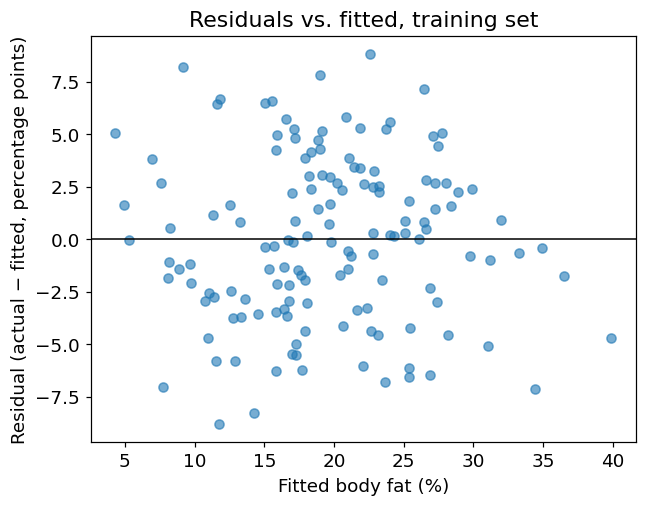

            age  weight_lb  height_in   bmi  neck  chest  abdomen   hip  \
age        1.00      -0.06      -0.13  0.05  0.09   0.10     0.16 -0.10   
weight_lb -0.06       1.00       0.21  0.92  0.85   0.90     0.90  0.95   
height_in -0.13       0.21       1.00 -0.04  0.20   0.09     0.04  0.07   
bmi        0.05       0.92      -0.04  1.00  0.82   0.92     0.93  0.90   
neck       0.09       0.85       0.20  0.82  1.00   0.80     0.79  0.77   
chest      0.10       0.90       0.09  0.92  0.80   1.00     0.91  0.82   
abdomen    0.16       0.90       0.04  0.93  0.79   0.91     1.00  0.87   
hip       -0.10       0.95       0.07  0.90  0.77   0.82     0.87  1.00   
thigh     -0.26       0.88       0.02  0.86  0.72   0.75     0.78  0.91   
knee       0.02       0.85       0.14  0.76  0.69   0.73     0.75  0.82   
ankle     -0.13       0.76       0.22  0.66  0.61   0.63     0.59  0.69   
biceps    -0.11       0.78       0.15  0.74  0.73   0.71     0.67  0.72   
forearm   -0.12       0.5

In [31]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

# --- TODO: fit least squares on all 14 measurements ---
ols            = LinearRegression().fit(X_train, y_train)  # the fitted model, or the weight vector from the normal equations
pred_train_ols = ols.predict(X_train)
pred_val_ols   = ols.predict(X_val)

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- TODO: print each weight with its units; plot residuals against fitted values; show the correlations ---
units = {
    "age": "years", "weight_lb": "lb", "height_in": "in", "bmi": "kg/m²",
    "neck": "cm", "chest": "cm", "abdomen": "cm", "hip": "cm", "thigh": "cm",
    "knee": "cm", "ankle": "cm", "biceps": "cm", "forearm": "cm", "wrist": "cm",
}
for name, coef in zip(predictors, ols.coef_):
    print(f"{name}: {coef:.4f} per {units[name]}")
resid = y_train - pred_train_ols

plt.scatter(pred_train_ols, resid, alpha=0.6)
plt.axhline(0, color="k", lw=1)
plt.xlabel("Fitted body fat (%)")
plt.ylabel("Residual (actual − fitted, percentage points)")
plt.title("Residuals vs. fitted, training set")
plt.show()

#Feature vs. Feature

corr_mat = pd.DataFrame(np.corrcoef(X_train.T), index=measurements, columns=measurements)
print(corr_mat.round(2))

#Feature vs Body Fat % (y values), [0,1] gives off diagonal results
corrs = pd.Series(
    [np.corrcoef(X_train[:, j], y_train)[0, 1] for j in range(X_train.shape[1])],
    index=measurements,
)
print(f'Correlation between Features and Body Fat \n {corrs}')

**Answer 4** — Which weights have a sign opposite to their feature's correlation with body fat, and why.
Weight, bmi, neck, hip, ankle, and wrist have opposite values when comparing weights to feature vs body fat % where the correlation was positive but the values for the weights were actually negative. This is due to multicollinearity, most notably with abdomen which can be seen in the table as positively correlated with all of these variables, hips have a 0.95 and 0.9 correlation with weight and BMI (with weight and BMI having a 0.92 correlation between them), and the other features tend have correlations anywhere between 0.5-0.8. But we cannot conclude whether the predictors are strong or weak by the weights alone because they are not standardized, and so they're unit dependent.

---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 2    validation RMSE there: 4.49    (least squares: 4.53)


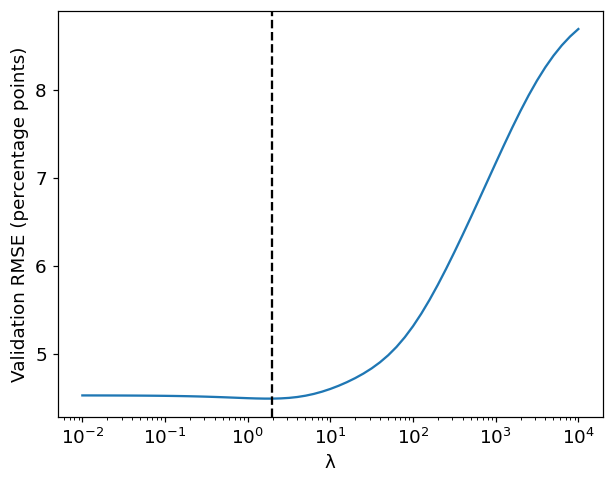

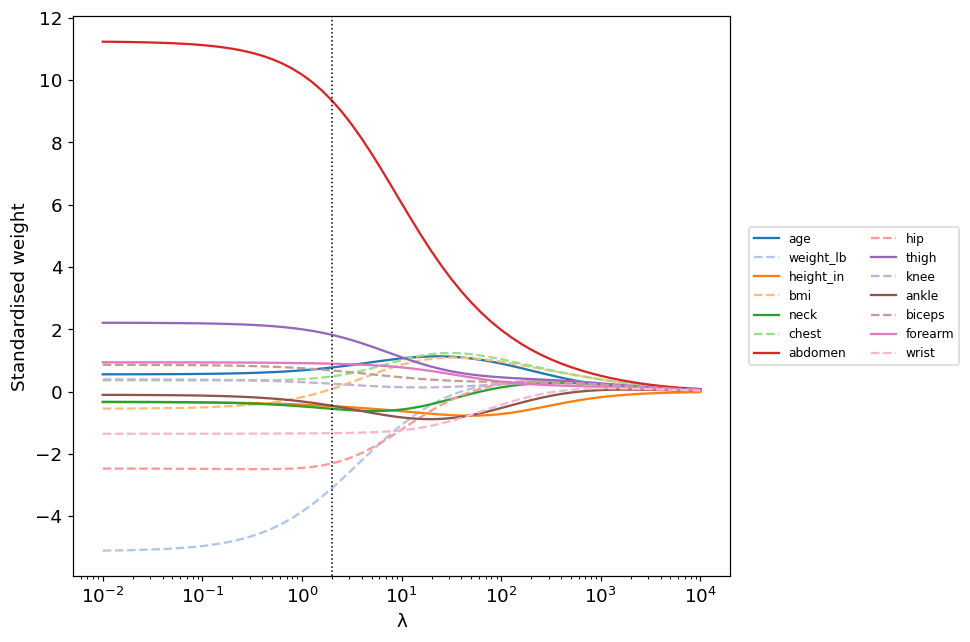

In [32]:
from sklearn.linear_model import Ridge

mu, sd         = X_train.mean(axis=0), X_train.std(axis=0, ddof=1)            # TODO: training-set mean and standard deviation of each measurement, shape (14,)
Z_train, Z_val = (X_train -mu)/sd, (X_val - mu)/sd            # TODO: standardised training and validation features

# --- TODO: fit Ridge for every lambda; collect the validation RMSE and the weight vectors ---
lambdas   = np.logspace(-2, 4, 61)
weights = []
val_rmse = []
train_err = []

for lam in lambdas:
  model = Ridge(alpha=lam).fit(Z_train, y_train)
  weights.append(model.coef_)
  val_rmse.append(rmse(y_val, model.predict(Z_val)))
  train_err.append(rmse(y_train, model.predict(Z_train)))

weights         = np.array(weights)   # one row of weights per lambda
val_rmse = np.array(val_rmse)
train_error = np.array(train_err)

best_idx = np.argmin(val_rmse)
best_lambda = lambdas[best_idx]


#val_rmse    = val_err                     # array, one entry per lambda
#weights     = W                     # array of shape (len(lambdas), 14)
#best_lambda = lam_best

assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# --- TODO: the two plots ---
plt.figure()
plt.plot(lambdas, val_rmse)
plt.xscale("log")
plt.axvline(best_lambda, color="k", ls="--")
plt.xlabel("λ")
plt.ylabel("Validation RMSE (percentage points)")
plt.show()

#plt.figure(figsize=(8, 5))
#for j, name in enumerate(measurements):
 #   plt.plot(lambdas, weights[:, j], label=name)
#plt.xscale("log")
#plt.axvline(best_lambda, color="k", ls="--")
#plt.xlabel("λ")
#plt.ylabel("Standardised weight")
#plt.legend(ncol=2, fontsize=7)
#plt.show()

plt.figure(figsize=(9, 6))
colors = plt.cm.tab20(np.linspace(0, 1, 20))[:14]     # 20 distinct colors, take 14
styles = ["-", "--"] * 7                               # alternate solid/dashed

for j, name in enumerate(measurements):
    plt.plot(lambdas, weights[:, j], label=name, color=colors[j], ls=styles[j])

plt.xscale("log")
plt.axvline(best_lambda, color="k", ls=":", lw=1)
plt.xlabel("λ")
plt.ylabel("Standardised weight")
plt.legend(ncol=2, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

**Answer 5** — Which $\lambda$ you chose and how; which weights the penalty shrinks first and why.
I picked the lambda where the val_rmse is minimized, which gives me a value of 2. The penalty modestly shrinks the weights, as seen with the validation RMSE being 4.49 whereas for OLS it was 4.53. This makes sense since ridge regression is more valuable to prevent overfitting when you have a small sample size, but since our training data has ~141 men, the penalty doesn't have a big effect. The penalty seems to shrink weight_lb and abdomen the most, although abdomen remains as the feature with highest standardized weight but weight_lb becomes similar in weight to hip, which makes sense given how correlated the two variables are.

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [33]:
#By looking at the correlations, abdomen definetely seems like one of the features I want to keep since it has the highest correlation to body fat.
#But the next 2 highly correlated features, bmi and chest, are also highly correlated with abdomen. Forearm doesn't seem like a bad choice, since
#it's only moderately correlated with abdomen, but it also weakly correlated with body fat percentage. Biceps may be a better choice (moderate-high
#correlation with abdomen but moderate correlation with body fat percentage).
def partial_corrs(chosen_names):
    j = [measurements.index(c) for c in chosen_names]
    #Train model with just abdomen as a feature, at first
    base = LinearRegression().fit(X_train[:, j], y_train)
    y_res = y_train - base.predict(X_train[:, j])          # what's left of body fat
    out = {}
    for k, name in enumerate(measurements):
        if k in j:
            continue
        #Try to predict the other features given only abdomen data.
        cand = LinearRegression().fit(X_train[:, j], X_train[:, k])
        x_res = X_train[:, k] - cand.predict(X_train[:, j])  # what's new in the candidate
        #Correlation between the residual of what couldn't be predicted by
        #abdomen in body fat percentage
        #and the residual/what couldn't be predicted by abdomen against each other
        #feature
        out[name] = np.corrcoef(x_res, y_res)[0, 1]
    return pd.Series(out).sort_values(key=abs, ascending=False)

print(partial_corrs(['abdomen']))
print(partial_corrs(['abdomen', 'weight_lb']))

weight_lb   -0.487008
hip         -0.412098
ankle       -0.348605
wrist       -0.333878
height_in   -0.290464
neck        -0.277730
knee        -0.239075
thigh       -0.198424
bmi         -0.186552
age          0.179951
chest       -0.175273
biceps      -0.116332
forearm     -0.028841
dtype: float64
forearm      0.225481
biceps       0.220175
thigh        0.200007
wrist       -0.160180
height_in   -0.123496
bmi          0.082907
knee         0.079801
hip         -0.075776
age         -0.063724
chest        0.054147
ankle       -0.040721
neck        -0.021992
dtype: float64


In [34]:
# --- TODO: choose up to three measurements and fit least squares on them ---
chosen         = ['weight_lb', 'abdomen', 'biceps']                  # a list of 1 to 3 column names from `measurements`
small_df = clean[['weight_lb', 'abdomen', 'biceps', 'body_fat_pct']]

new_X_all = small_df[chosen].values
new_y_all = small_df['body_fat_pct'].values

# Done for you: the test set, 25% of the men, identical for every student.
Xs_dev, Xs_test, ys_dev, ys_test = train_test_split(new_X_all, new_y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
Xs_train, Xs_val, ys_train, ys_val = train_test_split(Xs_dev, ys_dev, test_size = 0.25, random_state=9400)

small          =  LinearRegression().fit(Xs_train, ys_train)                 # the fitted model
pred_train_small = small.predict(Xs_train)
pred_val_small = small.predict(Xs_val)
small_val_rmse = rmse(ys_val, pred_val_small)
ridge_val_rmse = val_rmse.min()

assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")

['weight_lb', 'abdomen', 'biceps']: validation RMSE 4.52   (full least squares 4.53, ridge 4.49, mean 9.08)


**Answer 6** — Your choice of measurements and the evidence for it. Abdomen, chest and bmi have the highest correlation with body fat percentage (0.78, 0.67, 0.68). But BMI seems highly correlated with chest, abdomen, and neck, so we want a different feature to provide new information, but it must also be highly correlated with body fat percentage.I was going to pick forearm because it's moderately correlated with abdomen (0.44), but it was weakly correlated with body fat percentage (0.33). My next option was biceps because it was moderately correlated with body fat percentage (0.46), but it was moderately high correlated with abdomen (0.67). Since I was struggling to pick the next 2 features, I trained a linear regression model to predict body fat percentage from only the abdomen as a feature, determined the residual, then trained another linear regression model on the abdomen and every other feature to get the residual for each feature. Then I get the correlation coefficients of the residuals, and took the next highest feature, weight_lb and did the same process with weight_lb and abdomen as the only features. Ultimately, the 3 feature was between biceps and forearm again, so I picked biceps since it has a higher correlation with body fat percentage, but either feature could be used. So my features were: Abdomen, weight_lb, and biceps.

---



---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

                  model  test RMSE  test R^2
       predict the mean      8.533    -0.000
     least squares (14)      4.907     0.669
             ridge (14)      4.787     0.685
3-feature least squares      4.836     0.679


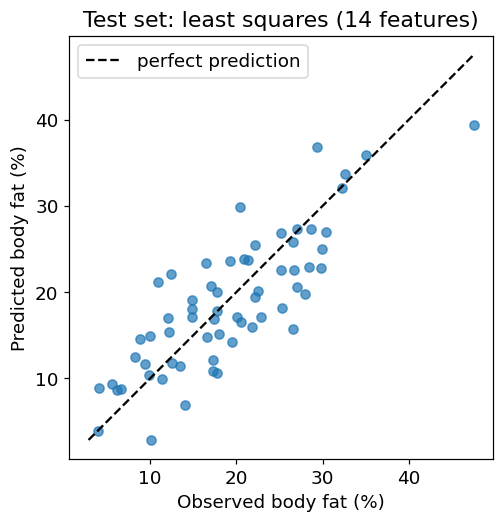

In [35]:
# --- TODO: refit each model on the development set and evaluate on the test set ---

# I didn't hyperparametrize the full dataset yet, I need to compute least square
# on all 14 measurements

pred_mean = np.full_like(y_test, y_dev.mean(), dtype=float)
ols_final = LinearRegression().fit(X_dev, y_dev)
pred_ols = ols_final.predict(X_test)

mu_dev, sd_dev = X_dev.mean(axis=0), X_dev.std(axis=0, ddof=1)
ridge_final = Ridge(alpha=best_lambda).fit((X_dev -mu_dev)/sd_dev, y_dev)
pred_ridge = ridge_final.predict((X_test- mu_dev)/sd_dev)

small_dev = LinearRegression().fit(Xs_dev, ys_dev)
pred_small_dev = small_dev.predict(Xs_test)
#small2_val_rmse = rmse(ys_test, pred_val_small_2)
rows = []
for name, pred in [('predict the mean', pred_mean),
                   ('least squares (14)', pred_ols),
                   ('ridge (14)', pred_ridge), ('3-feature least squares', pred_small_dev)]:
                   rows.append({'model': name, 'test RMSE': rmse(y_test, pred), "test R^2": r_squared(y_test, pred)})

results = pd.DataFrame(rows)         # a DataFrame with the columns ["model", "test RMSE", "test R^2"] and four rows

assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- TODO: predicted against observed on the test set, with the diagonal ---
lo = min(y_test.min(), pred_ols.min())
hi = max(y_test.max(), pred_ols.max())

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_ols, alpha=0.7)
plt.plot([lo, hi], [lo, hi], "k--", label="perfect prediction")
plt.xlabel("Observed body fat (%)")
plt.ylabel("Predicted body fat (%)")
plt.title("Test set: least squares (14 features)")
plt.legend()
plt.gca().set_aspect("equal")
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

### Report

**1. The task.** X are body measurements, y is the body fat percentage.The sample is made up of 251 men measured at BYU.

**2. Data decisions.** Before fitting, I checked for height < 50 inches or body fat pecentage <= 0. Case 42 was 29.5 inches tall, recalculating with BMI and weight, his height was 69.4 inches, which was much more reasonable. Case 182 had a body fat % of 0 and an impossible body density, so the subject was dropped. I  excluded density to prevent data leakage (Siri's equation)

**3. Results.**
Mean Baseline: test RMSE: 8.533, test R^2 = -0.000
Predicted value is average target value, our baseline.
OLS: test RMSE: 4.907, test R^2: 0.669
Error decreased significantly. Explains 2/3rds of the variance in the model.
Ridge: test RMSE: 4.787, test R^2 = 0.685
RMSE slightly lower, helps with correlated features. 69% of the variance is explained by the 14 parameters.
3-feature OLS: test RMSE: 4.836, test R^2: 0.679
Similar performance to ridge and OLS, 3 features are enough in determining the target (explaining 68% of the variance). RMSE differences ~0.1, so I don't rank the models.

**4. Two weights.**
Abdomen = 1.07 body fat % points per cm and the correlation with body fat percentage is 0.782, which is consistent. However, weight_lb = -0.1691 body fat points per lb with a correlation to body fat % of 0.568, the change in sign indicates multicollinearity, the weight acts as a correction.

**5. Limitations.**
Sample size is made up of middle aged men from BYU and may not be accurate for different sexes and age groups, etc. Weights on correlated features can be unstable.

**6. Recommendation.**
The clinic should measure the abdomen and bicep circumferences and weigh the person to determine body fat percentage, There is an error of +-4.8 percentage points.

---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement** — Claude, used it to write some code, debugging, and helping me shorten down my answers/report and critique the wording. I also used it to explain the questions if there was confusing wording.

### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.